In [8]:
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from google.colab import drive
import os
import numpy as np
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

100%|██████████| 170M/170M [1:02:36<00:00, 45.4kB/s]


Epoch 1/10, Loss: 2.2081
Epoch 2/10, Loss: 2.0136
Epoch 3/10, Loss: 1.9298
Epoch 4/10, Loss: 1.8822
Epoch 5/10, Loss: 1.8459
Epoch 6/10, Loss: 1.8165
Epoch 7/10, Loss: 1.7923
Epoch 8/10, Loss: 1.7720
Epoch 9/10, Loss: 1.7541
Epoch 10/10, Loss: 1.7382

Training accuracy: 39.49%
Test accuracy: 39.43%


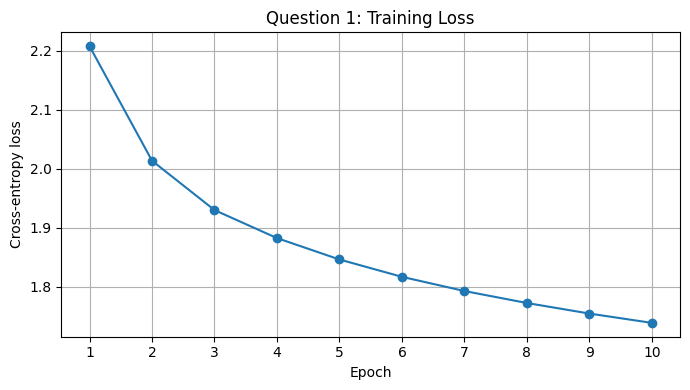

In [10]:
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

data_path = "/content/drive/MyDrive/CIFAR10"

transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,)*3, (0.5,)*3)])
trainset = torchvision.datasets.CIFAR10(root=data_path, train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root=data_path, train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=50, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=50, shuffle=False)

Din, H, K = 3072, 100, 10
torch.manual_seed(0)
W1, b1 = torch.randn(Din, H)*0.01, torch.zeros(H)
W2, b2 = torch.randn(H, K)*0.01, torch.zeros(K)
lr, epochs, train_losses = 0.01, 10, []

for epoch in range(epochs):
    total_loss = 0
    for inputs, labels in trainloader:
        X = inputs.reshape(inputs.size(0), -1)
        N = X.size(0)
        Y = F.one_hot(labels, K).float()

        # Forward pass
        Z1 = X @ W1 + b1
        A1 = torch.sigmoid(Z1)
        logits = A1 @ W2 + b2
        probs = torch.softmax(logits, dim=1)
        loss = -(Y * torch.log(probs.clamp(min=1e-12))).sum() / N

        # Backpropagation
        dlogits = (probs - Y) / N
        dW2, db2 = A1.T @ dlogits, dlogits.sum(dim=0)
        dA1 = dlogits @ W2.T
        dZ1 = dA1 * A1 * (1 - A1)
        dW1, db1 = X.T @ dZ1, dZ1.sum(dim=0)

        # Update parameters
        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2
        total_loss += loss.item()

    avg_loss = total_loss / len(trainloader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            X = inputs.reshape(inputs.size(0), -1)
            logits = torch.sigmoid(X @ W1 + b1) @ W2 + b2
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

train_acc = accuracy(trainloader)
test_acc = accuracy(testloader)
print(f"\nTraining accuracy: {train_acc:.2f}%")
print(f"Test accuracy: {test_acc:.2f}%")

# 6. Plot training loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs+1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Question 1: Training Loss")
plt.xticks(range(1, epochs+1))
plt.grid(True)
plt.tight_layout()
plt.show()

Using device: cuda
LeNet-5 | Epoch 1/10 | Train loss: 0.4275 | Test loss: 0.1590 | Train acc: 87.91% | Test acc: 95.22%
LeNet-5 | Epoch 2/10 | Train loss: 0.1307 | Test loss: 0.0893 | Train acc: 96.05% | Test acc: 97.27%
LeNet-5 | Epoch 3/10 | Train loss: 0.0851 | Test loss: 0.0668 | Train acc: 97.36% | Test acc: 97.91%
LeNet-5 | Epoch 4/10 | Train loss: 0.0638 | Test loss: 0.0676 | Train acc: 98.07% | Test acc: 97.88%
LeNet-5 | Epoch 5/10 | Train loss: 0.0508 | Test loss: 0.0618 | Train acc: 98.46% | Test acc: 97.95%
LeNet-5 | Epoch 6/10 | Train loss: 0.0439 | Test loss: 0.0577 | Train acc: 98.62% | Test acc: 98.31%
LeNet-5 | Epoch 7/10 | Train loss: 0.0367 | Test loss: 0.0537 | Train acc: 98.83% | Test acc: 98.37%
LeNet-5 | Epoch 8/10 | Train loss: 0.0321 | Test loss: 0.0504 | Train acc: 98.98% | Test acc: 98.51%
LeNet-5 | Epoch 9/10 | Train loss: 0.0271 | Test loss: 0.0438 | Train acc: 99.15% | Test acc: 98.58%
LeNet-5 | Epoch 10/10 | Train loss: 0.0244 | Test loss: 0.0460 | Train a

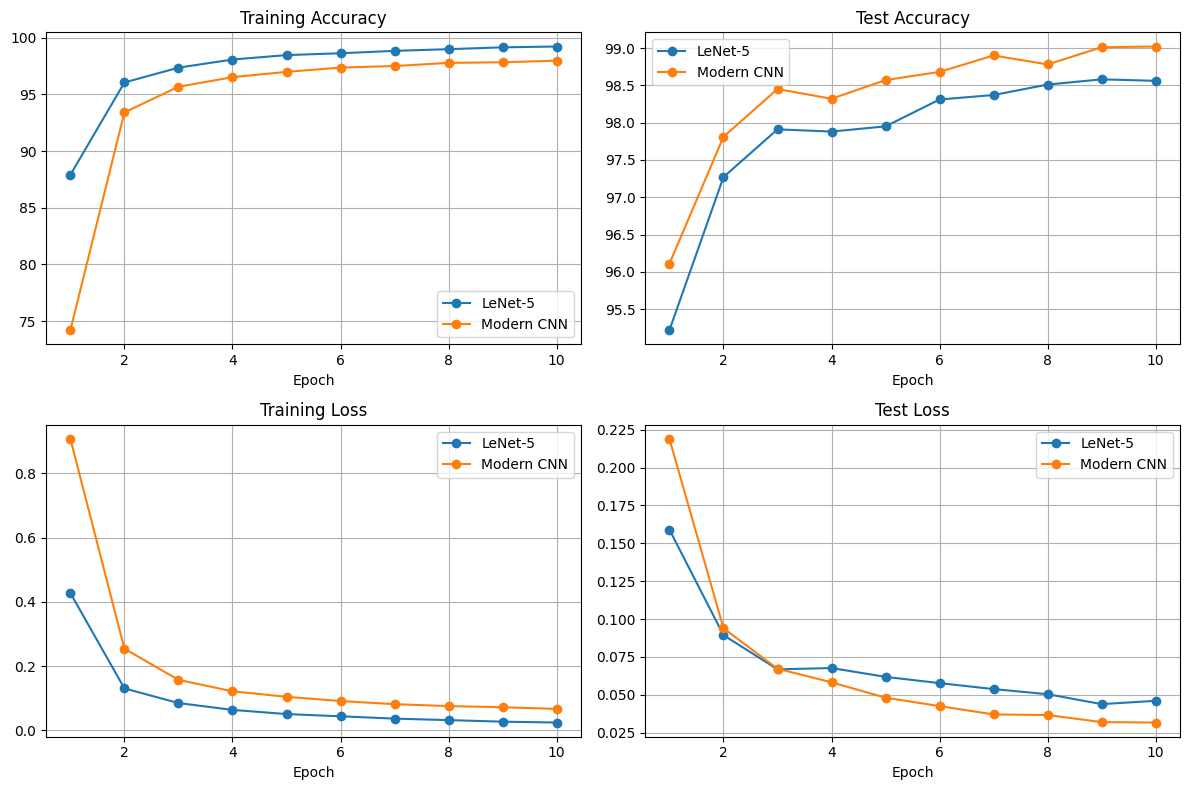

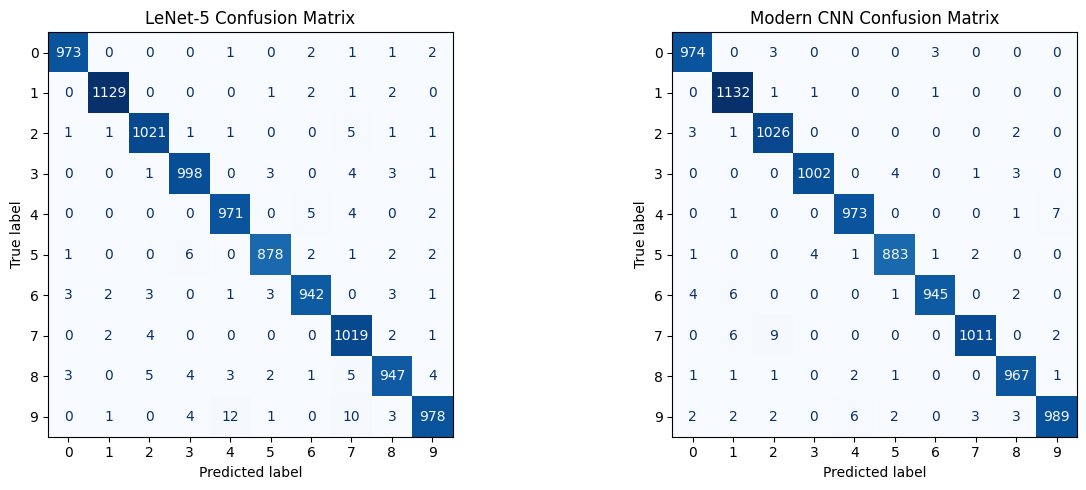


FINAL RESULTS AFTER 10 EPOCHS
LeNet-5: Train 99.22%, Test 98.56%
Modern CNN: Train 97.97%, Test 99.02%


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

transform = transforms.ToTensor()
trainset = torchvision.datasets.MNIST(root="/content/drive/MyDrive/MNIST", train=True,download=True, transform=transform)
testset = torchvision.datasets.MNIST(root="/content/drive/MyDrive/MNIST", train=False,download=True, transform=transform)
torch.manual_seed(0)
trainloader = DataLoader(trainset, batch_size=128, shuffle=True)
testloader = DataLoader(testset, batch_size=256, shuffle=False)

# LeNet5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16*4*4, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

# Modern CNN
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(), nn.MaxPool2d(2), nn.Dropout2d(0.10),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(), nn.MaxPool2d(2), nn.Dropout2d(0.15),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128),
            nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.30), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

def run_model(model, name, epochs=10):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "test_loss": [],
               "train_acc": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct, train_total = 0, 0, 0

        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * y.size(0)
            train_correct += (logits.argmax(1) == y).sum().item()
            train_total += y.size(0)

        history["train_loss"].append(train_loss / train_total)
        history["train_acc"].append(100 * train_correct / train_total)

        model.eval()
        test_loss, test_correct, test_total = 0, 0, 0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for x, y in testloader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                loss = criterion(logits, y)
                preds = logits.argmax(1)

                test_loss += loss.item() * y.size(0)
                test_correct += (preds == y).sum().item()
                test_total += y.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(y.cpu().numpy())

        history["test_loss"].append(test_loss / test_total)
        history["test_acc"].append(100 * test_correct / test_total)

        print(f"{name} | Epoch {epoch+1}/{epochs} | "
              f"Train loss: {history['train_loss'][-1]:.4f} | "
              f"Test loss: {history['test_loss'][-1]:.4f} | "
              f"Train acc: {history['train_acc'][-1]:.2f}% | "
              f"Test acc: {history['test_acc'][-1]:.2f}%")

    return model, history, all_labels, all_preds

lenet, h_lenet, y_true, pred_lenet = run_model(LeNet5(), "LeNet-5")
modern, h_modern, _, pred_modern = run_model(ModernCNN(), "Modern CNN")

epochs = range(1, 11)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

for h, name in [(h_lenet, "LeNet-5"), (h_modern, "Modern CNN")]:
    ax[0, 0].plot(epochs, h["train_acc"], marker="o", label=name)
    ax[0, 1].plot(epochs, h["test_acc"], marker="o", label=name)
    ax[1, 0].plot(epochs, h["train_loss"], marker="o", label=name)
    ax[1, 1].plot(epochs, h["test_loss"], marker="o", label=name)

ax[0, 0].set_title("Training Accuracy")
ax[0, 1].set_title("Test Accuracy")
ax[1, 0].set_title("Training Loss")
ax[1, 1].set_title("Test Loss")

for a in ax.flat:
    a.set_xlabel("Epoch")
    a.grid(True)
    a.legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for a, preds, name in [
    (ax[0], pred_lenet, "LeNet-5 Confusion Matrix"),
    (ax[1], pred_modern, "Modern CNN Confusion Matrix")]:
    cm = confusion_matrix(y_true, preds, labels=list(range(10)))
    ConfusionMatrixDisplay(cm, display_labels=list(range(10))).plot(
        ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)

plt.tight_layout()
plt.show()

print("\nFINAL RESULTS AFTER 10 EPOCHS")
print(f"LeNet-5: Train {h_lenet['train_acc'][-1]:.2f}%, "
      f"Test {h_lenet['test_acc'][-1]:.2f}%")
print(f"Modern CNN: Train {h_modern['train_acc'][-1]:.2f}%, "
      f"Test {h_modern['test_acc'][-1]:.2f}%")


### Question 2 — Results and Discussion

Both LeNet-5 and the modern CNN were trained on MNIST for 10 epochs. LeNet-5 achieved 99.22% training accuracy and 98.56% test accuracy. The modern CNN achieved 97.95% training accuracy and 99.02% test accuracy.

The modern CNN performed better on the test set, achieving higher test accuracy and lower test loss. LeNet-5 achieved higher training accuracy, but its test performance was slightly lower. The confusion matrices show that both models correctly classify most handwritten digits. Overall, the modern CNN demonstrated better generalization to unseen test images in this experiment.